In [38]:
import os
import re
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

# Define paths for your files inside the data folder
file1 = os.path.join("data", "student_ai_tool_usage_dataset.csv")
file2 = os.path.join("data", "ai_student_impact_dataset (1).csv")
file3 = os.path.join("data", "ai_assistant_usage_student_life.csv")
file4 = os.path.join("data", "higher_education_students_performance.csv")


# 1. Primary Dataset 1
try:
    df_p1 = pd.read_csv(file1)
except FileNotFoundError:
    # Fallback if named without _dataset
    df_p1 = pd.read_csv(os.path.join("data", "student_ai_tool_usage.csv"))

print("=== PRIMARY DATASET 1: Student AI Tool Usage ===")
print("Shape:", df_p1.shape)
print("Data Types:\n", df_p1.dtypes)
print("\n" + "=" * 50 + "\n")

# 2. Primary Dataset 2
df_p2 = pd.read_csv(file2)
print("=== PRIMARY DATASET 2: AI Student Impact ===")
print("Shape:", df_p2.shape)
print("Data Types:\n", df_p2.dtypes)
print("\n" + "=" * 50 + "\n")

# 3. Secondary Dataset 1
df_s1 = pd.read_csv(file3)
print("=== SECONDARY DATASET 1: AI Assistant Usage ===")
print("Shape:", df_s1.shape)
print("Data Types:\n", df_s1.dtypes)

# 4. Secondary Dataset 2
df_s2 = pd.read_csv(file4)

print("=== SECONDARY DATASET 2: Higher Education Students Performance ===")
print("Shape:", df_s2.shape)
print("Data Types:\n", df_s2.dtypes)
print("\nFirst 5 rows:\n", df_s2.head())



=== PRIMARY DATASET 1: Student AI Tool Usage ===
Shape: (200, 8)
Data Types:
 timestamp               object
student_id              object
ai_tool_used            object
usage_hours_per_week    object
purpose                 object
satisfaction_level       int64
academic_performance    object
comments                object
dtype: object


=== PRIMARY DATASET 2: AI Student Impact ===
Shape: (50000, 16)
Data Types:
 Student_ID                      int64
Major_Category                 object
Year_of_Study                  object
Pre_Semester_GPA              float64
Weekly_GenAI_Hours            float64
Primary_Use_Case               object
Prompt_Engineering_Skill       object
Tool_Diversity                  int64
Paid_Subscription                bool
Traditional_Study_Hours       float64
Perceived_AI_Dependency         int64
Institutional_Policy           object
Anxiety_Level_During_Exams      int64
Post_Semester_GPA             float64
Skill_Retention_Score         float64
Burnout_Ris

In [ ]:
# print(df_p1['usage_hours_per_week'].unique())
# ['2' '12' '1.5' '3' 'Everytime ' '4 or 6 hours ' '20 hours may be'
#  '2-3 hours' '5' '7 hours' '74' '10hrs' '21' '40-50' '15' '8 to 10'
#  'Unlimited ' '1 hour' '2 to 3 hours' '4,hours ' '25' '24 h' '3 Hours '
#  '3 to 4 hours' '14hr' '10' 'Limited in paper otherwise rare' '14' '9' '1'
#  '4' '13' '6' '11' '7' '8']

# this function is used to convert the values 
# in df_p1['usage_hours_per_week'] (object type) into real numbers 
def to_hours(x):
    s = str(x).strip().lower()

    # text answers with no usable number (plain text)
    text_words = ["everytime", "unlimited", "rare"]
    for word in text_words:
        if word in s:
            return np.nan

    # pull every number out of the text (such as '4 or 6 hours ' -> ["4", "6"])
    found = re.findall(r"\d+\.?\d*", s)

    nums = []
    for n in found:
        nums.append(float(n))

    # no numbers found -> nothing usable
    if len(nums) == 0:
        return np.nan

    # add the numbers up, then divide by how many there are.
    # one number returns itself; a range returns the average
    total = 0
    for n in nums:
        total += n

    return total / len(nums)


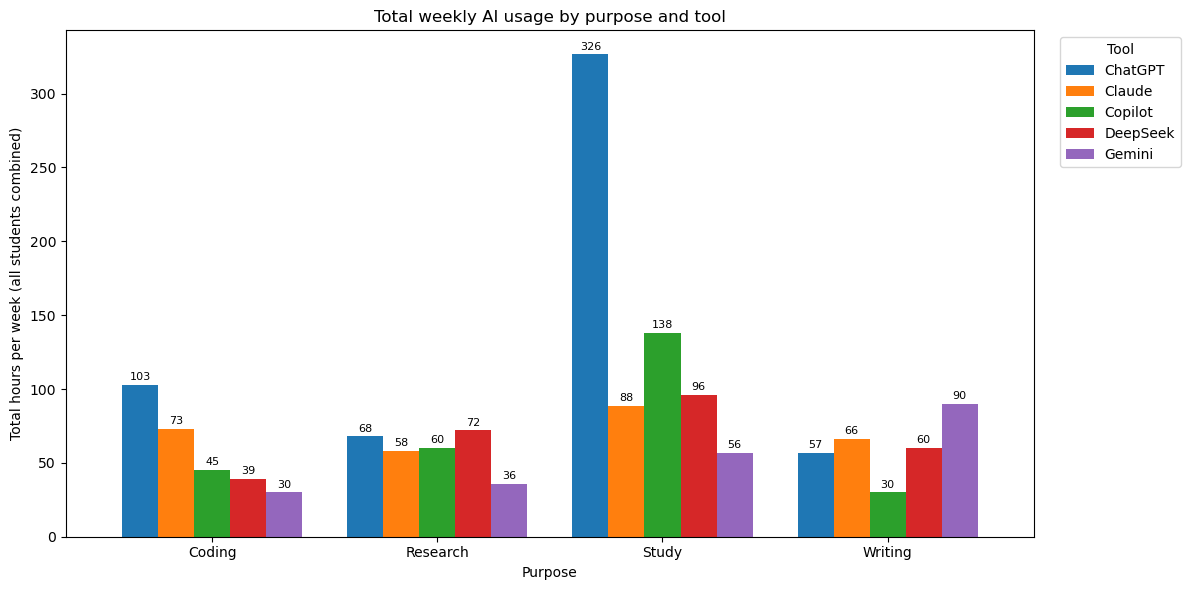

In [48]:
# THIS PLOT TRY TO SHOW THE TOTAL WEEKLY AI USAGE BY PURPOSE AND TOOL

df_p1["usage_hours_raw"] = df_p1["usage_hours_per_week"]               # keep the original
df_p1["usage_hours_per_week"] = df_p1["usage_hours_raw"].apply(to_hours)

# 
df_p1["ai_tool_used"] = df_p1["ai_tool_used"].str.strip().str.lower()
df_p1["ai_tool_used"] = df_p1["ai_tool_used"].replace({"claudeai": "claude"})
df_p1["ai_tool_used"] = df_p1["ai_tool_used"].str.title().replace({"Chatgpt": "ChatGPT", "Deepseek": "DeepSeek"})

df_p1["purpose"] = df_p1["purpose"].str.strip().str.lower()

# the free-text row ("ChatGPT is used for many different tasks.")
df_p1.loc[df_p1["purpose"].str.contains("many different tasks", na=False), "purpose"] = "other"
df_p1["purpose"] = df_p1["purpose"].str.title()

# print(df_p1["ai_tool_used"].unique())
# print(df_p1["purpose"].unique())

purpose_tool = df_p1.pivot_table(
    index="purpose",
    columns="ai_tool_used",
    values="usage_hours_per_week",
    aggfunc="mean",
    margins=True,
    margins_name="All"
).round(2)

# purpose_tool

purpose_tool_sum = df_p1.pivot_table(index="purpose", columns="ai_tool_used",
                                 values="usage_hours_per_week", aggfunc="sum")

# print(purpose_tool_sum)
purpose_tool_sum = purpose_tool_sum.drop(index='Other')

ax = purpose_tool_sum.plot(kind="bar", figsize=(12, 6), width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)

ax.set_xlabel("Purpose")
ax.set_ylabel("Total hours per week (all students combined)")
ax.set_title("Total weekly AI usage by purpose and tool")
ax.legend(title="Tool", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()